# VERA 스타일 판단 기준 학습 (Verbalized Learning)

[VERA](https://smcho1201.tistory.com/146) 아이디어를 단순화해서 실습합니다. **모델 가중치는 전혀 학습하지 않고**, 사람이 읽을 수 있는 **자연어 판단 기준(guideline)**을 스스로 개선해 나가는 과정을 직접 구현합니다.

- QLoRA(2번), Vision Adapter(5번) 노트북은 RunPod GPU에서 가중치를 학습했습니다.
- 이 노트북은 **가중치 업데이트가 전혀 없어** Ollama만으로 실행됩니다(이 저장소의 `Dockerfile`로 만든 RunPod Pod에는 Ollama와 모델이 이미 설치되어 있습니다).
- 결과물도 벡터가 아니라 사람이 읽고 고칠 수 있는 **문장**이라는 점이 핵심입니다.
- `1. VLM 학습 데이터 준비.ipynb`가 HuggingFace Hub에 업로드한 ChartQA_KOR 데이터로
  "차트를 보고 질문에 답하는 방식"에 대한 guideline을 개선합니다.



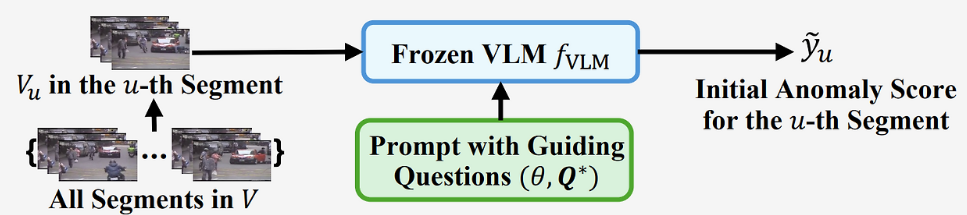

## 사전 준비
1. `.env.example`을 `.env`로 복사하고 `HF_TOKEN`, `HF_DATASET_REPO_ID`(노트북 1에서 업로드한 repo)를 채워넣기
```bash
cp .env.example .env
uv sync
```
2. Docker(RunPod Pod) 없이 로컬에서 직접 실행하는 경우에만 [Ollama](https://ollama.com)를 설치하고 모델을 받아두기
```bash
ollama pull qwen3-vl:4b-instruct
```

In [1]:
import os

from dotenv import load_dotenv
from PIL import Image

import vlm_finetune_utils as vu

load_dotenv()
HF_TOKEN = os.environ["HF_TOKEN"]
HF_DATASET_REPO_ID = os.environ["HF_DATASET_REPO_ID"]

vu.download_dataset_from_hub("data", HF_DATASET_REPO_ID, token=HF_TOKEN)


'data'에 이미 다운로드되어 있어 건너뜁니다.


## 1. 초기 판단 기준
사람이 대충 적어본 규칙에서 출발합니다 — 일부러 허점(자유로운 문장으로 설명하라는 지시가
`judge_answer`의 엄격한 매칭과 충돌하는 지점)을 남겨두었습니다.

In [2]:
INITIAL_GUIDELINE = "차트를 꼼꼼히 살펴보고, 근거와 함께 친절하고 자세한 문장으로 답하라."

PROMPT_TEMPLATE = """당신은 차트 이미지를 보고 질문에 답하는 도우미입니다. 아래 판단 기준에
따라 이 차트 이미지를 보고 질문에 답하세요.

[질문]
{question}

[답변 기준]
{guideline}

답변만 출력하세요. 다른 설명은 하지 마세요.
"""


## 2. 평가 함수
주어진 guideline으로 데이터셋 전체를 검사하고, `judge_answer`(ChartQA relaxed accuracy) 기준
정확도와 틀린 사례를 반환합니다.

In [3]:
def evaluate(guideline, records, image_root):
    results = []
    for r in records:
        img = Image.open(f"{image_root}/{r['image']}")
        prompt = PROMPT_TEMPLATE.format(question=r["question"], guideline=guideline)
        try:
            pred = vu.ask_image(img, prompt)
        except Exception:
            pred = ""

        correct = vu.judge_answer(pred, r["answer"])
        results.append({"record": r, "pred": pred, "correct": correct})

    accuracy = sum(x["correct"] for x in results) / len(results)
    return accuracy, results


## 3. 초기 기준으로 학습셋 평가
로컬 Ollama 호출은 느리므로, 실습에서는 학습셋 중 `N_TRAIN`개만 사용합니다.

In [4]:
N_TRAIN = 20  # 로컬 Ollama 호출 속도를 고려한 서브셋 크기

train_records = vu.load_jsonl("data/train/annotations.jsonl")[:N_TRAIN]

accuracy, results = evaluate(INITIAL_GUIDELINE, train_records, "data/train")
print(f"초기 정확도: {accuracy:.0%}")


초기 정확도: 0%


## 4. 틀린 사례를 요약해 판단 기준 재작성
VERA의 핵심 아이디어: **틀린 사례를 모델 스스로에게 보여주고, 더 나은 기준을 자연어로 다시 쓰게** 합니다. 정답 라벨이 없는 실서비스라면 사람 피드백으로 대체할 수 있는 단계입니다.

In [5]:
def summarize_mistakes(results, max_examples=5):
    mistakes = [r for r in results if not r["correct"]][:max_examples]
    if not mistakes:
        return "(틀린 사례 없음)"

    lines = []
    for m in mistakes:
        r = m["record"]
        lines.append(
            f"- 질문: {r['question']} / 정답: {r['answer']!r}({len(r['answer'])}자) "
            f"/ 모델 답변: {m['pred']!r}({len(m['pred'])}자)"
        )
    return "\n".join(lines)


def refine_guideline(guideline, mistakes_text):
    prompt = f"""당신은 차트 질의응답 답변 기준을 개선하는 역할입니다.

[채점 방식]
모델 답변은 정답과 자동으로 비교됩니다: 숫자 답은 5% 오차까지, 텍스트 답은 정답과
글자 단위로 완전히 일치해야만 정답으로 인정됩니다. 부연 설명, 단위, 조사가 붙거나
문장 형태로 답하면 정답과 글자가 달라져 오답 처리됩니다.

[현재 판단 기준]
{guideline}

[이 기준으로 틀린 사례들 — 정답과 모델 답변의 글자 수 차이를 눈여겨보세요]
{mistakes_text}

위 틀린 사례들의 공통 원인을 분석해서, 자동 채점을 통과할 수 있도록
판단 기준을 2~4문장의 자연어 지침으로 다시 작성해줘. 지침 문장만 출력하고
다른 설명은 하지 마."""
    return vu.ask_text(prompt)


## 5. 여러 라운드 반복
라운드마다 (평가 → 틀린 사례 요약 → 기준 재작성)을 반복하며 기준이 어떻게 바뀌는지 관찰합니다.

In [6]:
N_ROUNDS = 3
guideline = INITIAL_GUIDELINE
history = []

for round_no in range(1, N_ROUNDS + 1):
    accuracy, results = evaluate(guideline, train_records, "data/train")
    history.append({"round": round_no, "guideline": guideline, "accuracy": accuracy})
    print(f"--- Round {round_no} ---")
    print(f"정확도: {accuracy:.0%}")
    print(f"기준: {guideline}\n")

    mistakes_text = summarize_mistakes(results)
    guideline = refine_guideline(guideline, mistakes_text)

final_guideline = guideline


--- Round 1 ---
정확도: 0%
기준: 차트를 꼼꼼히 살펴보고, 근거와 함께 친절하고 자세한 문장으로 답하라.

--- Round 2 ---
정확도: 35%
기준: 정답과 완전히 일치하는 문자열로만 답변해야 합니다. 숫자는 5% 오차 내에서만 인정되며, 단위나 부연 설명, 문장 형태는 포함되지 않습니다. 차트 내용을 정확히 파악하고, 질문에 직접 대응하는 최소한의 글자 수로 답하십시오.

--- Round 3 ---
정확도: 35%
기준: 정답 문자열과 완전히 일치해야 합니다. 숫자는 5% 오차 내에서만 인정되며, 단위, 부연 설명, 문장 형태, 조사 등은 포함되지 않습니다. 차트 내용을 정확히 파악하고 질문에 직접 대응하는 최소한의 글자 수로 답하십시오. 모델 답변이 정답과 문자가 달라도 오답 처리되므로, 정확성과 간결함을 동시에 확보해야 합니다.



## 6. 기준 변화와 정확도 추이 확인

In [7]:
for h in history:
    print(f"[Round {h['round']}] 정확도 {h['accuracy']:.0%}")
    print(f"  {h['guideline']}\n")

print("최종 기준:")
print(final_guideline)


[Round 1] 정확도 0%
  차트를 꼼꼼히 살펴보고, 근거와 함께 친절하고 자세한 문장으로 답하라.

[Round 2] 정확도 35%
  정답과 완전히 일치하는 문자열로만 답변해야 합니다. 숫자는 5% 오차 내에서만 인정되며, 단위나 부연 설명, 문장 형태는 포함되지 않습니다. 차트 내용을 정확히 파악하고, 질문에 직접 대응하는 최소한의 글자 수로 답하십시오.

[Round 3] 정확도 35%
  정답 문자열과 완전히 일치해야 합니다. 숫자는 5% 오차 내에서만 인정되며, 단위, 부연 설명, 문장 형태, 조사 등은 포함되지 않습니다. 차트 내용을 정확히 파악하고 질문에 직접 대응하는 최소한의 글자 수로 답하십시오. 모델 답변이 정답과 문자가 달라도 오답 처리되므로, 정확성과 간결함을 동시에 확보해야 합니다.

최종 기준:
정답 문자열과 완전히 일치해야 하며, 숫자는 5% 오차 내에서만 인정됩니다. 단위, 부연 설명, 문장 형태, 조사 등은 포함되지 않아야 합니다. 차트 내용을 정확히 파악하고 질문에 직접 대응하는 최소한의 글자 수로 답해야 하며, 문자가 달라도 오답 처리되므로 간결함과 정확성을 동시에 확보해야 합니다.


## 7. 검증셋(val)으로 최종 기준 확인
학습에 쓰지 않은 데이터로 최종 판단 기준의 일반화 성능을 확인합니다.

In [8]:
N_VAL = 20  # 로컬 Ollama 호출 속도를 고려한 서브셋 크기

val_records = vu.load_jsonl("data/val/annotations.jsonl")[:N_VAL]

initial_val_acc, _ = evaluate(INITIAL_GUIDELINE, val_records, "data/val")
final_val_acc, _ = evaluate(final_guideline, val_records, "data/val")

print(f"초기 기준 - val 정확도: {initial_val_acc:.0%}")
print(f"최종 기준 - val 정확도: {final_val_acc:.0%}")


초기 기준 - val 정확도: 0%
최종 기준 - val 정확도: 15%


## 정리
- 이 노트북에서 학습된 것은 **가중치가 아니라 문장**입니다 — `final_guideline`을 그대로 읽고, 사람이 직접 수정해서 다시 사용할 수도 있습니다.
- Prompt Tuning(soft prompt)의 결과물은 사람이 읽을 수 없는 벡터인 반면, VERA류 접근의 결과물은 **해석 가능한 텍스트**라는 차이를 기억하세요.
- GPU/가중치 학습 없이도 답변 형식(간결한 단답 vs 장문 설명)처럼 "프롬프트로 설명 가능한 규칙"은 개선할 수 있지만, 차트를 잘못 읽어서 생기는 오류처럼 모델의 시각적 인식 능력 자체에 기인한 오류는 고치기 어렵습니다 — 이 한계를 넘어서려면 다시 QLoRA 같은 가중치 학습이 필요합니다.